<a href="https://colab.research.google.com/github/mcarden4-netizen/Homework-Intro-to-ML/blob/Homework/Homework6Part1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
drive.mount('/content/drive')

filetest = '/content/drive/My Drive/Housing.csv'
data = pd.read_csv('/content/drive/My Drive/Housing.csv')
data.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [22]:
Y = data['price'].astype(float)
X = data.drop(columns = ['price']).copy()

yesno = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']

for col in yesno:
    X[col] = X[col].map({'yes': 1, 'no': 0})

X = pd.get_dummies(X, columns=['furnishingstatus'], dtype=int)
X = X.astype(np.float32)

In [23]:
Xtrain, Xtest, Ytrain, Ytest = train_test_split(X, Y, test_size=0.2, random_state=50)

In [24]:
scaler = StandardScaler()

Xtrain = scaler.fit_transform(Xtrain).astype(np.float32)
Xtest = scaler.transform(Xtest).astype(np.float32)

Ytrain = Ytrain.to_numpy(dtype=np.float32) / 1e6
Ytest = Ytest.to_numpy(dtype=np.float32)

In [26]:
Xfit, Xval, Yfit, Yval = train_test_split(Xtrain, Ytrain, test_size=0.20, random_state=50)

torch.manual_seed(50)
np.random.seed(50)

Xfit = torch.tensor(Xfit, dtype=torch.float32)
Yfit = torch.tensor(Yfit, dtype=torch.float32).reshape(-1, 1)

Xval = torch.tensor(Xval, dtype=torch.float32)
Yval = torch.tensor(Yval, dtype=torch.float32).reshape(-1, 1)

Xtrain_tensor = torch.tensor(Xtrain, dtype=torch.float32)
Ytrain_tensor = torch.tensor(Ytrain, dtype=torch.float32).reshape(-1, 1)

Xtest_tensor = torch.tensor(Xtest, dtype=torch.float32)

In [40]:
class Housing(nn.Module):
  def __init__(self, input_size):
    super().__init__()

    self.hidden_linear1 = nn.Linear(input_size, 64)
    self.hidden_act1 = nn.ReLU()

    self.hidden_linear2 = nn.Linear(64, 32)
    self.hidden_act2 = nn.ReLU()

    self.output_linear = nn.Linear(32, 1)

  def forward(self, input):
    hidden = self.hidden_linear1(input)
    active = self.hidden_act1(hidden)

    hidden = self.hidden_linear2(active)
    active = self.hidden_act2(hidden)

    output = self.output_linear(active)

    return output

In [41]:
model = Housing(Xtrain.shape[1])

In [43]:
learning_rate = 0.001
epochs = 5000

means = nn.MSELoss()

optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

train_losses = []
val_losses = []

best_val_loss = float('inf')

In [44]:
for epoch in range(epochs):

    model.train()

    optimizer.zero_grad()

    predictions = model(Xfit)
    loss = means(predictions, Yfit)

    loss.backward()
    optimizer.step()

    train_loss = loss.item()

    model.eval()

    with torch.no_grad():
        val_predictions = model(Xval)
        val_loss = means(val_predictions, Yval).item()

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss

    if (epoch + 1) % 500 == 0:
        print(f"Epoch {epoch + 1}: " f"Training Loss = {train_loss:.6f}, " f"Validation Loss = {val_loss:.6f}")

print("Best validation loss:", best_val_loss)

Epoch 500: Training Loss = 0.775687, Validation Loss = 1.260563
Epoch 1000: Training Loss = 0.551006, Validation Loss = 1.319656
Epoch 1500: Training Loss = 0.318271, Validation Loss = 1.559953
Epoch 2000: Training Loss = 0.148696, Validation Loss = 2.149834
Epoch 2500: Training Loss = 0.070019, Validation Loss = 2.846971
Epoch 3000: Training Loss = 0.035347, Validation Loss = 3.495508
Epoch 3500: Training Loss = 0.018809, Validation Loss = 4.114523
Epoch 4000: Training Loss = 0.014938, Validation Loss = 4.295537
Epoch 4500: Training Loss = 0.013256, Validation Loss = 4.390934
Epoch 5000: Training Loss = 0.012068, Validation Loss = 4.597971
Best validation loss: 1.2570170164108276


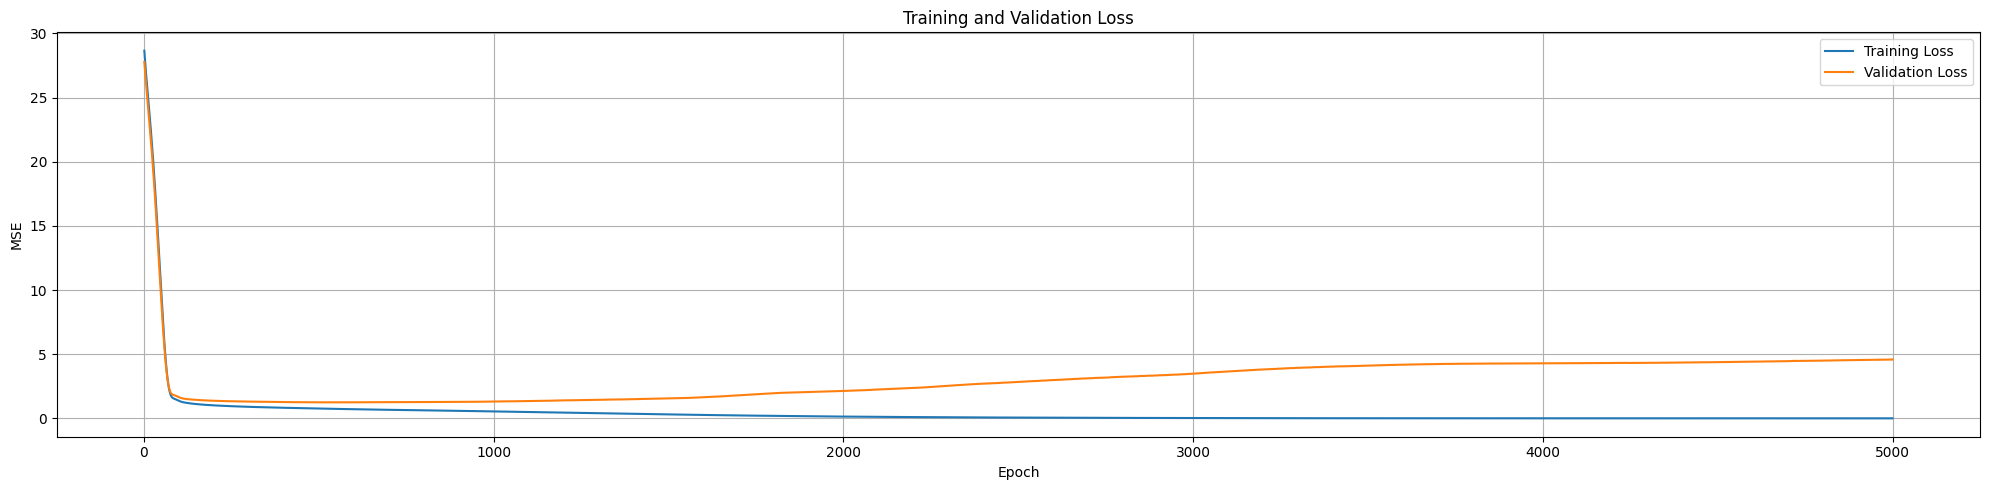

In [48]:
plt.figure(figsize=(20, 5))

plt.plot(range(1, epochs + 1), train_losses, label='Training Loss')

plt.plot(range(1, epochs + 1), val_losses,label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [55]:
torch.manual_seed(50)

final_model = Housing(Xtrain.shape[1])

final_optimizer = torch.optim.Adam(
    final_model.parameters(),
    lr=learning_rate
)

for epoch in range(epoch):

    final_model.train()

    final_optimizer.zero_grad()

    predictions = final_model(Xtrain_tensor)
    loss = means(predictions, Ytrain_tensor)

    loss.backward()
    final_optimizer.step()

In [56]:
final_model.eval()

with torch.no_grad():
    predictions = final_model(Xtest_tensor).numpy().flatten()

# Convert prices back to original currency units
predictions = predictions * 1e6

mse = mean_squared_error(Ytest, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(Ytest, predictions)

print("\n========== Neural Network Test Results ==========")
print(f"MSE:  {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²:   {r2:.4f}")



========== Neural Network Test Results ==========
MSE:  1026568683520.00
RMSE: 1013197.26
R²:   0.6981
